# Lambda jumps in spectral bandwidth selection

**Experiment 1:** draw 1,000 independent $N(0,1)$ samples of size $n=200$. For each sample, repeat the full Figure 3.3 lambda sweep and record the adjacent lambda pair containing its largest upward bandwidth-index change. Plot a histogram with one bin per lambda pair, and inspect the sizes of these changes separately.

Run the cells in order. Defaults reproduce Figure 3.3's numerical settings: 201 geometric bandwidths on $[0.01,2]$, 101 geometric lambda values on $[0.01,10^4]$, and the shared FFT divergence and stabilized Perron solver. Each sample stays fixed throughout its lambda sweep. The 1,000-sample results are checkpointed and reused when this notebook is rerun with the same settings.

The detector is an **operational finite-grid definition**, proposed for this experiment. A largest upward change can be small or tied; finding it does not establish a discontinuity or a statistically significant change point. The notebook records ties, samples with no upward change, and numerical failures explicitly.

Sources: [Figure 3.3 computation, cell `stationary-example-lambda-sensitivity`](spectral_scale_selection_kde.ipynb); [shared bandwidth grid](kde_tools/bandwidths.py); [FFT divergence implementation](kde_tools/fourier/similarities.py); [Perron solver and peak-selection convention](kde_tools/perron.py).

In [1]:
from __future__ import annotations

import hashlib
import json
import os
import sys
import time
from pathlib import Path

working_directory = Path.cwd().resolve()
code_directory = next(
    (candidate.resolve()
     for root in (working_directory, *working_directory.parents)
     for candidate in (root, root / "Code" / "Code_kde")
     if (candidate / "kde_tools" / "pdf_export.py").is_file()),
    None,
)
if code_directory is None:
    raise FileNotFoundError("Run this notebook from MASTERARBEIT or Code/Code_kde.")
if str(code_directory) not in sys.path:
    sys.path.insert(0, str(code_directory))
os.environ.setdefault("MPLCONFIGDIR", str(code_directory / ".matplotlib-cache"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
from threadpoolctl import threadpool_limits

from kde_tools.bandwidths import bandwidth_grid_linear_in_psi_beta
from kde_tools.fourier import beta2_divergence_matrix_fft
from kde_tools.pdf_export import enable_automatic_pdf_saving
from kde_tools.perron import (
    PERRON_SOLVER_VERSION,
    PerronConvergenceError,
    PerronDegeneracyError,
    perron_eigenpair_from_divergence,
)

notebook_name = "spectral_lambda_jump_study"
pdf_output_directory = enable_automatic_pdf_saving(
    notebook_name, output_root=code_directory / "outputs" / "pdfs"
)
data_root = code_directory / "outputs" / "data" / notebook_name
image_output_directory = code_directory / "outputs" / "images" / notebook_name
print(f"Automatic PDF exports: {pdf_output_directory}")
print(f"Perron solver: {PERRON_SOLVER_VERSION}")

Automatic PDF exports: /Users/iljasukhanov/MASTERARBEIT/Code/Code_kde/outputs/pdfs/spectral_lambda_jump_study
Perron solver: stabilized_lanczos_v1


## What counts as a jump in this experiment?

For repetition $r$, let $i_{r,k}$ be the zero-based selected bandwidth index at $\lambda_k$. Define

$$d_{r,k}=i_{r,k+1}-i_{r,k}, \qquad
k_r^*=\min\operatorname{arg\,max}_{0\leq k<100}d_{r,k}.$$

If $\max_k d_{r,k}>0$, record the pair $(\lambda_{k_r^*},\lambda_{k_r^*+1})$. Otherwise record **no upward change**. When several pairs share the largest positive change, the earliest pair is selected for the histogram; all tied pair indices and their count are saved in the results table. This is an explicit tie convention, not evidence that a single transition has been identified.

On the geometric bandwidth grid, my algebraic observation is that $d_{r,k}$ is proportional to $\log(h_{i_{r,k+1}}/h_{i_{r,k}})$. Thus this rule also selects the largest upward multiplicative bandwidth change. All lambda intervals have the same width in log space, so one histogram bin represents one adjacent pair. No interval midpoint is treated as an observed transition point.

The grid is `np.geomspace(1e-2, 1e4, 101)`, equivalently $\lambda_k=10^{-2+0.06k}$. NumPy specifies geometric spacing in its [geomspace documentation](https://numpy.org/doc/stable/reference/generated/numpy.geomspace.html); adjacent differences and first-maximum behavior are documented in [diff](https://numpy.org/doc/stable/reference/generated/numpy.diff.html) and [argmax](https://numpy.org/doc/stable/reference/generated/numpy.argmax.html).

In [2]:
# Experiment 1: full run. Change M for a short preview.
M = 1000
SAMPLE_SIZE = 200
SEED = 20261013
NORMAL_MEAN = 0.0
NORMAL_STD = 1.0

N_BANDWIDTHS = 201
H_MIN, H_MAX = 0.01, 2.0
BANDWIDTH_GRID_BETA = 2.0  # Keep geometric spacing for the index-based detector.
LAMBDA_VALUES = np.geomspace(1e-2, 1e4, 101)
FFT_HALF_WIDTH = 12.0
FFT_SPATIAL_POINTS = 8192

CHECKPOINT_EVERY = 25
RETRY_NUMERICAL_FAILURES = False
CHECK_FIGURE_3_3 = True
# Presentation filter only: 1 includes every positive largest change.
# Increase this to inspect larger changes; it is an exploratory cutoff.
HISTOGRAM_MIN_STEPS = 1

if not isinstance(M, int) or M < 1 or SAMPLE_SIZE < 1:
    raise ValueError("M and SAMPLE_SIZE must be positive integers.")
if SEED < 0 or NORMAL_STD <= 0 or CHECKPOINT_EVERY < 1:
    raise ValueError("Require SEED >= 0, NORMAL_STD > 0, CHECKPOINT_EVERY >= 1.")
if BANDWIDTH_GRID_BETA != 2.0:
    raise ValueError("This experiment's index-based detector uses a geometric bandwidth grid.")
LAMBDA_VALUES = np.asarray(LAMBDA_VALUES, dtype=float)
if (LAMBDA_VALUES.ndim != 1 or len(LAMBDA_VALUES) < 3
        or not np.all(np.isfinite(LAMBDA_VALUES))
        or np.any(LAMBDA_VALUES <= 0) or np.any(np.diff(LAMBDA_VALUES) <= 0)):
    raise ValueError("Provide at least three finite, positive, increasing lambda values.")
if not np.allclose(np.diff(np.log(LAMBDA_VALUES)), np.diff(np.log(LAMBDA_VALUES))[0]):
    raise ValueError("Use a geometric lambda grid for this experiment.")

H_GRID = bandwidth_grid_linear_in_psi_beta(
    h_min=H_MIN, h_max=H_MAX, beta=BANDWIDTH_GRID_BETA, grid_size=N_BANDWIDTHS
)
print(f"M={M}, n={SAMPLE_SIZE}, bandwidth candidates={len(H_GRID)}, lambdas={len(LAMBDA_VALUES)}")
print(f"Adjacent lambda ratio: {LAMBDA_VALUES[1] / LAMBDA_VALUES[0]:.10f}")

M=1000, n=200, bandwidth candidates=201, lambdas=101
Adjacent lambda ratio: 1.1481536215


In [3]:
JUMP_RULE_VERSION = "largest_positive_index_step_first_tie_v1"


def largest_upward_jump(selected_indices, lambda_values, bandwidth_grid):
    """Summarize a complete path; do not invent a pair if no step is positive."""
    selected_indices = np.asarray(selected_indices, dtype=np.int64)
    lambda_values = np.asarray(lambda_values, dtype=float)
    bandwidth_grid = np.asarray(bandwidth_grid, dtype=float)
    if (selected_indices.ndim != 1 or selected_indices.shape != lambda_values.shape
            or len(selected_indices) < 3 or np.any(selected_indices < 0)
            or np.any(selected_indices >= len(bandwidth_grid))):
        raise ValueError("Require a complete, valid path on the supplied bandwidth grid.")
    steps = np.diff(selected_indices)
    largest_step = int(steps.max())
    if largest_step <= 0:
        return {
            "status": "no_upward_change", "pair_index": -1,
            "lambda_left": np.nan, "lambda_right": np.nan,
            "index_before": -1, "index_after": -1,
            "h_before": np.nan, "h_after": np.nan,
            "jump_steps": 0, "h_ratio": np.nan, "delta_h": np.nan,
            "runner_up_steps": 0, "n_tied_maxima": 0, "tied_pair_indices": "",
        }
    tied_pairs = np.flatnonzero(steps == largest_step)
    k = int(tied_pairs[0])
    before, after = int(selected_indices[k]), int(selected_indices[k + 1])
    h_before, h_after = float(bandwidth_grid[before]), float(bandwidth_grid[after])
    return {
        "status": "upward_change", "pair_index": k,
        "lambda_left": float(lambda_values[k]), "lambda_right": float(lambda_values[k + 1]),
        "index_before": before, "index_after": after,
        "h_before": h_before, "h_after": h_after,
        "jump_steps": largest_step, "h_ratio": h_after / h_before,
        "delta_h": h_after - h_before,
        "runner_up_steps": max(0, int(np.delete(steps, k).max())),
        "n_tied_maxima": len(tied_pairs),
        "tied_pair_indices": ";".join(map(str, tied_pairs.tolist())),
    }


def compute_selection_path(samples, bandwidth_grid, lambda_values,
                           half_width=12.0, spatial_points=8192):
    """Calculate D once per sample; reuse it for every lambda."""
    divergence = beta2_divergence_matrix_fft(
        samples=samples, h_grid=bandwidth_grid,
        half_width=half_width, spatial_points=spatial_points,
    )
    indices = np.empty(len(lambda_values), dtype=np.int32)
    residuals = np.empty(len(lambda_values))
    relative_gaps = np.empty(len(lambda_values))
    for k, lambda_value in enumerate(lambda_values):
        result = perron_eigenpair_from_divergence(divergence, float(lambda_value))
        indices[k] = result.selected_index
        residuals[k] = result.relative_residual
        relative_gaps[k] = result.relative_gap
    return indices, residuals, relative_gaps


# Detector checks: unique large change, tied maxima, no upward change,
# and unsigned input (the detector converts it before differencing).
_test_lambdas = np.geomspace(1, 100, 4)
_test_h = np.geomspace(0.01, 2, 10)
assert largest_upward_jump([1, 2, 7, 6], _test_lambdas, _test_h)["pair_index"] == 1
_tie = largest_upward_jump([1, 3, 3, 5], _test_lambdas, _test_h)
assert _tie["pair_index"] == 0 and _tie["n_tied_maxima"] == 2
assert _tie["tied_pair_indices"] == "0;2"
assert largest_upward_jump([3, 2, 2, 1], _test_lambdas, _test_h)["status"] == "no_upward_change"
assert largest_upward_jump(np.array([3, 2, 2, 1], dtype=np.uint16),
                           _test_lambdas, _test_h)["status"] == "no_upward_change"
print("Detector checks passed.")

Detector checks passed.


## Reproduce the Figure 3.3 reference

This check uses the figure's fixed seed 20260823 and its original settings independently of the Monte Carlo settings. It must recover lambda positions 54 and 55 (zero-based), bandwidth indices 91 and 114, and a 23-step increase. The reference comes from the [saved Figure 3.3 values](outputs/analysis/perron_figures_3_1_to_3_4/figure_3_3_comparison.csv). Set `CHECK_FIGURE_3_3=False` to skip this check in later exploratory runs.

In [4]:
if CHECK_FIGURE_3_3:
    reference_lambdas = np.geomspace(1e-2, 1e4, 101)
    reference_h_grid = bandwidth_grid_linear_in_psi_beta(grid_size=201)
    reference_samples = np.random.default_rng(20260823).normal(size=200)
    with threadpool_limits(limits=1):
        reference_indices, reference_residuals, reference_gaps = compute_selection_path(
            reference_samples, reference_h_grid, reference_lambdas
        )
    reference_jump = largest_upward_jump(reference_indices, reference_lambdas, reference_h_grid)
    assert reference_jump["pair_index"] == 54
    assert (reference_jump["index_before"], reference_jump["index_after"]) == (91, 114)
    assert reference_jump["jump_steps"] == 23
    print("Figure 3.3 reproduced:")
    print(json.dumps(reference_jump, indent=2))
    print(f"Maximum relative eigenpair residual: {reference_residuals.max():.3e}")
else:
    print("Figure 3.3 reference check skipped.")

Figure 3.3 reproduced:
{
  "status": "upward_change",
  "pair_index": 54,
  "lambda_left": 17.378008287493746,
  "lambda_right": 19.952623149688787,
  "index_before": 91,
  "index_after": 114,
  "h_before": 0.11142140949205241,
  "h_after": 0.2049212977328429,
  "jump_steps": 23,
  "h_ratio": 1.8391554968388706,
  "delta_h": 0.09349988824079049,
  "runner_up_steps": 2,
  "n_tied_maxima": 1,
  "tied_pair_indices": "54"
}
Maximum relative eigenpair residual: 9.812e-16


## Run or resume 1,000 independent samples

Repetition `r` uses `default_rng(SeedSequence([SEED, r]))`, so its sample is reproducible without depending on earlier repetitions or checkpoint boundaries. Raw samples, all 101 selected indices, and the residual/gap diagnostics are stored in a configuration-specific checkpoint. Numerical failures are recorded separately and excluded from the histogram; unfinished repetitions resume automatically. Enable `RETRY_NUMERICAL_FAILURES` to retry recorded solver failures.

Sources: [NumPy parallel random generation and SeedSequence](https://numpy.org/doc/stable/reference/random/parallel.html); [shared solver's residual and gap checks](kde_tools/perron.py). The sampling and checkpoint policy is a design choice for this notebook.

In [5]:
# Fingerprint settings and shared numerical source to avoid mixing configurations.
shared_source_files = [
    "kde_tools/perron.py", "kde_tools/bandwidths.py", "kde_tools/similarities.py",
    "kde_tools/fourier/similarities.py", "kde_tools/fourier/reconstruction.py",
]
configuration = {
    "M": M, "sample_size": SAMPLE_SIZE, "seed": SEED,
    "normal_mean": NORMAL_MEAN, "normal_std": NORMAL_STD,
    "sampling_rule": "default_rng_SeedSequence_seed_repetition_v1",
    "bandwidth_grid": H_GRID.tolist(), "lambda_values": LAMBDA_VALUES.tolist(),
    "fft_half_width": FFT_HALF_WIDTH, "fft_spatial_points": FFT_SPATIAL_POINTS,
    "perron_solver": PERRON_SOLVER_VERSION, "jump_rule": JUMP_RULE_VERSION,
    "numpy_version": np.__version__, "scipy_version": scipy.__version__,
    "shared_source_sha256": {
        name: hashlib.sha256((code_directory / name).read_bytes()).hexdigest()
        for name in shared_source_files
    },
}
configuration_json = json.dumps(configuration, sort_keys=True)
configuration_id = hashlib.sha256(configuration_json.encode()).hexdigest()[:12]
run_directory = data_root / configuration_id
run_directory.mkdir(parents=True, exist_ok=True)
run_image_directory = image_output_directory / configuration_id
run_image_directory.mkdir(parents=True, exist_ok=True)
checkpoint_path = run_directory / "checkpoint.npz"
(run_directory / "configuration.json").write_text(
    json.dumps(configuration, indent=2) + "\n", encoding="utf-8"
)

samples = np.vstack([
    np.random.default_rng(np.random.SeedSequence([SEED, r])).normal(
        loc=NORMAL_MEAN, scale=NORMAL_STD, size=SAMPLE_SIZE
    )
    for r in range(M)
])
selected_indices = np.full((M, len(LAMBDA_VALUES)), -1, dtype=np.int32)
relative_residuals = np.full(selected_indices.shape, np.nan)
relative_gaps = np.full(selected_indices.shape, np.nan)
finished = np.zeros(M, dtype=bool)
numerical_success = np.zeros(M, dtype=bool)
error_messages = np.full(M, "", dtype="<U1000")
if checkpoint_path.is_file():
    with np.load(checkpoint_path, allow_pickle=False) as cached:
        if str(cached["configuration_json"].item()) != configuration_json:
            raise ValueError("Checkpoint configuration mismatch.")
        if not np.array_equal(cached["samples"], samples):
            raise ValueError("Checkpoint samples do not match this sampling configuration.")
        for name in ["selected_indices", "relative_residuals", "relative_gaps",
                     "finished", "numerical_success", "error_messages"]:
            if cached[name].shape != globals()[name].shape:
                raise ValueError(f"Checkpoint shape mismatch for {name}.")
            globals()[name] = cached[name].copy()
    print(f"Loaded {finished.sum()}/{M} finished repetitions from {checkpoint_path}")
if RETRY_NUMERICAL_FAILURES:
    finished[finished & ~numerical_success] = False


def save_checkpoint():
    temporary_path = checkpoint_path.with_suffix(".npz.tmp")
    with temporary_path.open("wb") as stream:
        np.savez_compressed(
            stream, configuration_json=configuration_json, samples=samples,
            lambda_values=LAMBDA_VALUES, bandwidth_grid=H_GRID,
            selected_indices=selected_indices, relative_residuals=relative_residuals,
            relative_gaps=relative_gaps, finished=finished,
            numerical_success=numerical_success, error_messages=error_messages,
        )
    temporary_path.replace(checkpoint_path)


pending_repetitions = np.flatnonzero(~finished)
started = time.perf_counter()
print(f"Configuration {configuration_id}: {len(pending_repetitions)} repetitions to calculate.")
try:
    # Prevent a small matrix solve from launching excessive BLAS threads.
    with threadpool_limits(limits=1):
        for completed_this_run, r in enumerate(pending_repetitions, start=1):
            r = int(r)
            try:
                path, residuals, gaps = compute_selection_path(
                    samples[r], H_GRID, LAMBDA_VALUES,
                    half_width=FFT_HALF_WIDTH, spatial_points=FFT_SPATIAL_POINTS,
                )
            except (PerronConvergenceError, PerronDegeneracyError) as error:
                numerical_success[r] = False
                error_messages[r] = f"{type(error).__name__}: {error}"
                print(f"Recorded numerical failure at repetition {r}: {error}")
            else:
                selected_indices[r] = path
                relative_residuals[r] = residuals
                relative_gaps[r] = gaps
                numerical_success[r] = True
                error_messages[r] = ""
            finished[r] = True
            if completed_this_run % CHECKPOINT_EVERY == 0:
                save_checkpoint()
                elapsed = time.perf_counter() - started
                remaining = len(pending_repetitions) - completed_this_run
                eta = elapsed / completed_this_run * remaining
                print(f"Finished {finished.sum()}/{M}; elapsed {elapsed:.1f}s; remaining about {eta:.1f}s", flush=True)
finally:
    save_checkpoint()

print(f"Finished {finished.sum()}/{M}; numerically successful: {numerical_success.sum()}; failures: {(finished & ~numerical_success).sum()}")
print(f"Saved raw samples and trajectories: {checkpoint_path}")

Loaded 1000/1000 finished repetitions from /Users/iljasukhanov/MASTERARBEIT/Code/Code_kde/outputs/data/spectral_lambda_jump_study/2ce04db2a16e/checkpoint.npz
Configuration 2ce04db2a16e: 0 repetitions to calculate.
Finished 1000/1000; numerically successful: 1000; failures: 0
Saved raw samples and trajectories: /Users/iljasukhanov/MASTERARBEIT/Code/Code_kde/outputs/data/spectral_lambda_jump_study/2ce04db2a16e/checkpoint.npz


In [6]:
if not np.all(finished):
    raise RuntimeError("Resume the sampling cell before summarizing an incomplete experiment.")
records = []
for r in range(M):
    record = {"repetition": r, "sampling_seed": SEED}
    if numerical_success[r]:
        record.update(largest_upward_jump(selected_indices[r], LAMBDA_VALUES, H_GRID))
        record["max_relative_residual"] = float(relative_residuals[r].max())
        record["min_relative_gap"] = float(relative_gaps[r].min())
        record["error"] = ""
    else:
        record.update({"status": "numerical_failure", "pair_index": -1,
                       "jump_steps": np.nan, "error": error_messages[r]})
    records.append(record)
results = pd.DataFrame(records)
results.to_csv(run_directory / "jump_results.csv", index=False)

if not numerical_success.any():
    raise RuntimeError("All samples failed numerically. Inspect jump_results.csv before plotting.")
upward = results.loc[results["status"] == "upward_change"].copy()
counts = np.bincount(upward["pair_index"].to_numpy(dtype=int),
                     minlength=len(LAMBDA_VALUES) - 1)
unique_counts = np.bincount(
    upward.loc[upward["n_tied_maxima"] == 1, "pair_index"].to_numpy(dtype=int),
    minlength=len(LAMBDA_VALUES) - 1,
)
tied_counts = counts - unique_counts
pair_histogram = pd.DataFrame({
    "pair_index": np.arange(len(LAMBDA_VALUES) - 1),
    "lambda_left": LAMBDA_VALUES[:-1], "lambda_right": LAMBDA_VALUES[1:],
    "count": counts, "unique_maximum_count": unique_counts, "tied_maximum_count": tied_counts,
    "fraction_of_all_samples": counts / M,
    "fraction_of_upward_change_samples": counts / max(1, len(upward)),
})
pair_histogram.to_csv(run_directory / "lambda_pair_histogram.csv", index=False)
assert int(counts.sum()) == len(upward)
summary = {
    "configuration_id": configuration_id, "samples": M,
    "numerical_successes": int(numerical_success.sum()),
    "numerical_failures": int((~numerical_success).sum()),
    "samples_with_upward_change": len(upward),
    "samples_with_no_upward_change": int((results["status"] == "no_upward_change").sum()),
    "samples_with_tied_largest_changes": int((upward["n_tied_maxima"] > 1).sum()),
    "samples_with_largest_change_at_most_2_steps": int((upward["jump_steps"] <= 2).sum()),
    "samples_with_largest_change_at_least_5_steps": int((upward["jump_steps"] >= 5).sum()),
    "median_largest_upward_steps": float(upward["jump_steps"].median()) if len(upward) else None,
    "largest_relative_eigenpair_residual": float(np.nanmax(relative_residuals)) if numerical_success.any() else None,
}
(run_directory / "summary.json").write_text(json.dumps(summary, indent=2) + "\n", encoding="utf-8")
print(json.dumps(summary, indent=2))
print("\nMost frequent lambda pairs (earliest pair chosen in ties):")
print(pair_histogram.sort_values("count", ascending=False).head(10).to_string(index=False))

{
  "configuration_id": "2ce04db2a16e",
  "samples": 1000,
  "numerical_successes": 1000,
  "numerical_failures": 0,
  "samples_with_upward_change": 973,
  "samples_with_no_upward_change": 27,
  "samples_with_tied_largest_changes": 508,
  "samples_with_largest_change_at_most_2_steps": 483,
  "samples_with_largest_change_at_least_5_steps": 344,
  "median_largest_upward_steps": 3.0,
  "largest_relative_eigenpair_residual": 1.6975870221346365e-15
}

Most frequent lambda pairs (earliest pair chosen in ties):
 pair_index  lambda_left  lambda_right  count  unique_maximum_count  tied_maximum_count  fraction_of_all_samples  fraction_of_upward_change_samples
         57    26.302680     30.199517     46                    26                  20                    0.046                           0.047276
         58    30.199517     34.673685     42                    19                  23                    0.042                           0.043165
         70   158.489319    181.970086     40 

## Histogram of adjacent lambda pairs

Each bar counts samples whose largest positive index change occurred between that bin's two lambda endpoints. The horizontal axis is logarithmic; bar height is a sample count, not a probability density per unit lambda. The default `HISTOGRAM_MIN_STEPS=1` includes all positive largest changes. Raise it and rerun only the plot cell to inspect larger changes; the CSV histogram retains the unfiltered counts.

The orange interval marks the fixed sample's Figure 3.3 pair, approximately $(17.3780,19.9526)$. The darker bars count unique largest changes; the lighter portions count tied maxima allocated to their earliest pair. Their stacked heights give the requested total counts. Ties are also reported in the annotation. A secondary histogram shows change sizes, including zero for numerically successful samples with no upward change.

Saved PDF: /Users/iljasukhanov/MASTERARBEIT/Code/Code_kde/outputs/pdfs/spectral_lambda_jump_study/001_largest_upward_change_lambda_pair_histogram_m_1000_n_200_n_201.pdf


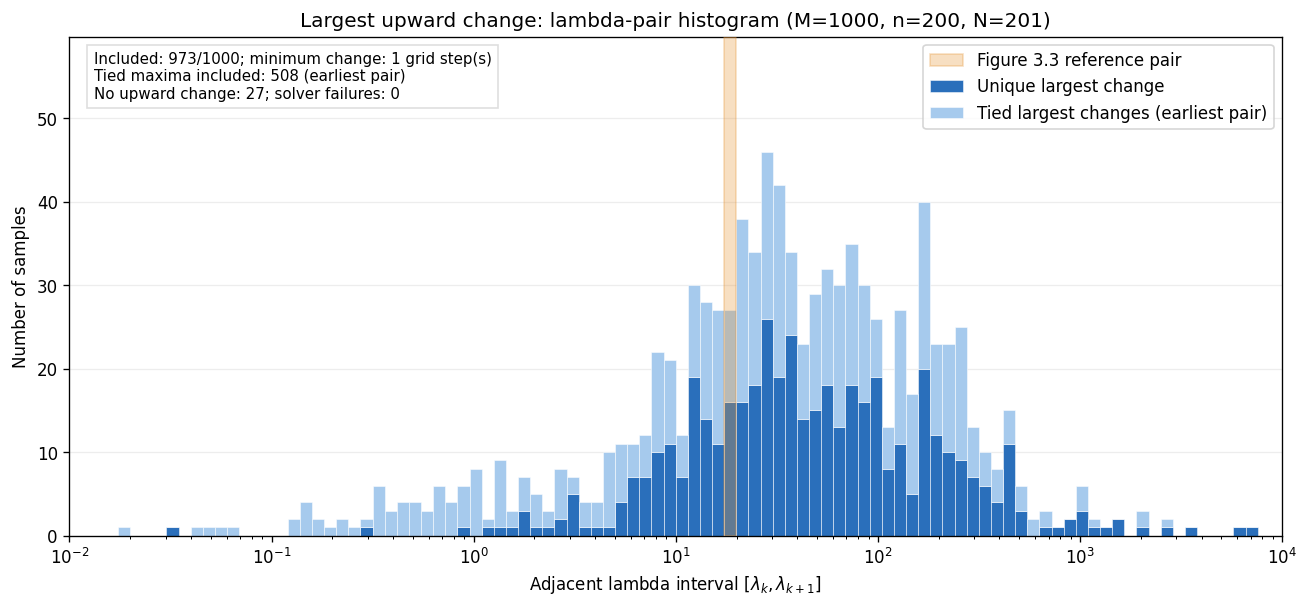

In [7]:
if not isinstance(HISTOGRAM_MIN_STEPS, int) or HISTOGRAM_MIN_STEPS < 1:
    raise ValueError("HISTOGRAM_MIN_STEPS must be a positive integer.")
plotted = upward.loc[upward["jump_steps"] >= HISTOGRAM_MIN_STEPS]
plot_counts = np.bincount(plotted["pair_index"].to_numpy(dtype=int),
                          minlength=len(LAMBDA_VALUES) - 1)
plot_unique_counts = np.bincount(
    plotted.loc[plotted["n_tied_maxima"] == 1, "pair_index"].to_numpy(dtype=int),
    minlength=len(LAMBDA_VALUES) - 1,
)
plot_tied_counts = plot_counts - plot_unique_counts
fig, ax = plt.subplots(figsize=(11, 5.2))
ax.bar(LAMBDA_VALUES[:-1], plot_unique_counts, width=np.diff(LAMBDA_VALUES),
       align="edge", color="#2a6fbb", edgecolor="white", linewidth=0.3,
       label="Unique largest change", zorder=2)
ax.bar(LAMBDA_VALUES[:-1], plot_tied_counts, width=np.diff(LAMBDA_VALUES),
       bottom=plot_unique_counts, align="edge", color="#a6caed", edgecolor="white",
       linewidth=0.3, label="Tied largest changes (earliest pair)", zorder=2)
ax.axvspan(17.378008287493746, 19.952623149688787, color="#e69536",
           alpha=0.3, label="Figure 3.3 reference pair", zorder=3)
ax.set_xscale("log")
ax.set_xlim(LAMBDA_VALUES[0], LAMBDA_VALUES[-1])
ax.set_ylim(0, max(1, int(plot_counts.max())) * 1.3)
ax.set_xlabel(r"Adjacent lambda interval $[\lambda_k,\lambda_{k+1}]$")
ax.set_ylabel("Number of samples")
ax.set_title(f"Largest upward change: lambda-pair histogram (M={M}, n={SAMPLE_SIZE}, N={len(H_GRID)})")
annotation = (
    f"Included: {len(plotted)}/{M}; minimum change: {HISTOGRAM_MIN_STEPS} grid step(s)\n"
    f"Tied maxima included: {int((plotted['n_tied_maxima'] > 1).sum())} (earliest pair)\n"
    f"No upward change: {summary['samples_with_no_upward_change']}; solver failures: {summary['numerical_failures']}"
)
ax.text(0.02, 0.97, annotation, transform=ax.transAxes, va="top", fontsize=9,
        bbox={"facecolor": "white", "edgecolor": "#dddddd", "alpha": 0.95})
ax.grid(axis="y", alpha=0.22, zorder=0)
ax.legend(loc="upper right")
fig.tight_layout()
fig.savefig(run_image_directory / f"lambda_pair_histogram_min_steps_{HISTOGRAM_MIN_STEPS}.png",
            dpi=150, bbox_inches="tight")
plt.show()  # Shared exporter automatically saves this figure as PDF.
plt.close(fig)

Saved PDF: /Users/iljasukhanov/MASTERARBEIT/Code/Code_kde/outputs/pdfs/spectral_lambda_jump_study/002_sizes_of_the_largest_upward_changes_1000_successful_samples.pdf


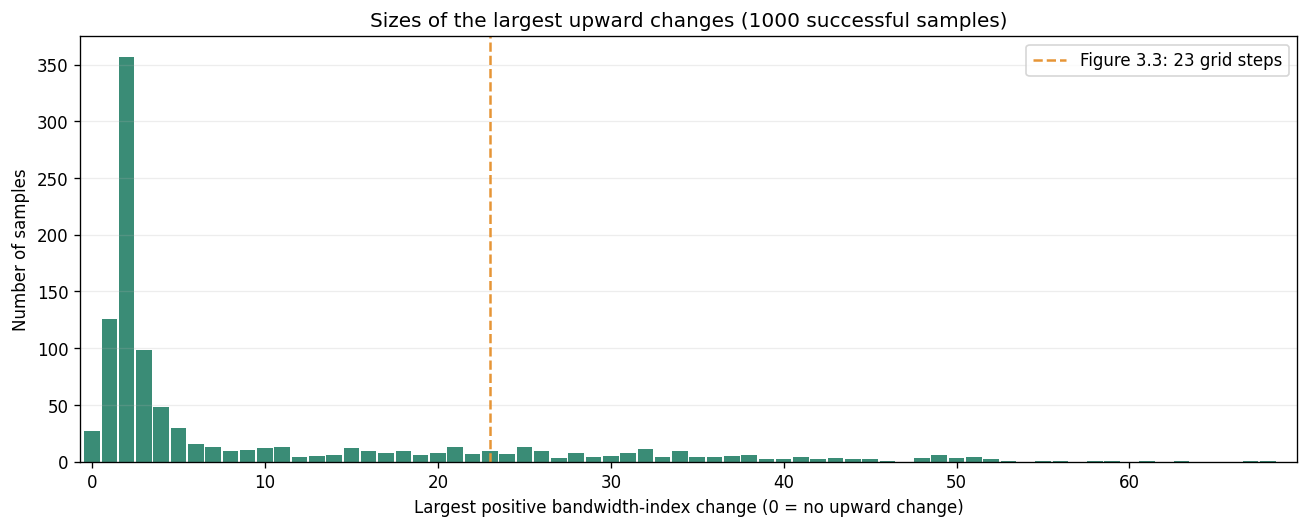

In [8]:
successful_results = results.loc[results["status"] != "numerical_failure"]
sizes = successful_results["jump_steps"].to_numpy(dtype=int)
size_counts = np.bincount(sizes, minlength=1)
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.bar(np.arange(len(size_counts)), size_counts, color="#3a8c76", width=0.9)
ax.axvline(23, color="#e69536", linestyle="--", label="Figure 3.3: 23 grid steps")
ax.set_xlim(-0.7, max(24, len(size_counts)) + 0.7)
ax.set_ylim(bottom=0)
ax.set_xlabel("Largest positive bandwidth-index change (0 = no upward change)")
ax.set_ylabel("Number of samples")
ax.set_title(f"Sizes of the largest upward changes ({len(successful_results)} successful samples)")
ax.grid(axis="y", alpha=0.22)
ax.legend()
fig.tight_layout()
fig.savefig(run_image_directory / "largest_upward_change_sizes.png", dpi=150, bbox_inches="tight")
plt.show()  # Shared exporter automatically saves this figure as PDF.
plt.close(fig)

## Interpretation and next experiments

Read the lambda-pair histogram together with the size histogram and the tie count. Repeated small steps can produce many equally large changes; allocating those to the earliest pair is a reproducible convention with a possible effect on the first histogram. The columns `n_tied_maxima`, `tied_pair_indices`, `jump_steps`, and `runner_up_steps` make this visible. The histogram is descriptive of this detector, distribution, sample size, bandwidth grid, and lambda grid.

The checkpoint preserves each sample and its complete selection path. Later experiments can refine lambda values inside the recorded brackets, compare competing Perron peaks, check sensitivity to grid resolution, or change the data distribution. A coarse-grid maximum alone does not verify a discontinuity; that remains a question for refinement and peak analysis.

Outputs for this configuration are `jump_results.csv`, `lambda_pair_histogram.csv`, `summary.json`, `configuration.json`, and `checkpoint.npz` in the printed data directory. The checkpoint contains `samples`, `selected_indices`, `relative_residuals`, `relative_gaps`, `lambda_values`, and `bandwidth_grid`. PNG previews are configuration-specific; every displayed figure also receives an automatic PDF under `outputs/pdfs/spectral_lambda_jump_study/`.

Implementation references: [original Figure 3.3 notebook](spectral_scale_selection_kde.ipynb); [shared FFT divergence](kde_tools/fourier/similarities.py); [shared solver](kde_tools/perron.py); [SciPy symmetric eigensolver documentation](https://docs.scipy.org/doc/scipy/reference/generated/scipy.sparse.linalg.eigsh.html). The jump rule, tie policy across lambda pairs, and exploratory filtering are original choices for this study.

## Experiment 2: do competing peaks exchange dominance under repeated sampling?

Reuse the **same 1,000 samples and the same grids** from Experiment 1. This experiment distinguishes three observations:

1. At least two resolved interior local maxima coexist at a sampled lambda.
2. The selected maximum changes between **separated peaks**, with a resolved valley between them.
3. The crossing profile contains exactly two peaks, or more than two.

The detector is an original numerical rule for this study. Interior peaks are counted with `scipy.signal.find_peaks` and minimum prominence $10^{-8}\max_i v_i$. This small relative filter excludes numerical fluctuations; it is not a statistical significance threshold. Sensitivity is also checked at relative prominences $10^{-10}$ and $10^{-6}$. Flat tops count as one peak; endpoints are excluded. Sources for the peak definition and prominence: [SciPy find_peaks, Notes](https://docs.scipy.org/doc/scipy/reference/generated/scipy.signal.find_peaks.html), [peak_prominences](https://docs.scipy.org/doc/scipy/reference/generated/scipy.signal.peak_prominences.html).

For each adjacent lambda pair whose selected indices differ by at least two grid positions (in either direction), split the bandwidth indices halfway between those selections. Numerically solve for equality of the highest component in each region using [Brent's method](https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.brentq.html). Count a switch only when both competing maxima are interior, are separated by an intervening valley deeper than the prominence filter, and their height ordering reverses just below/above the crossing. Movement of one peak through adjacent bandwidth candidates does not satisfy this rule.

This searches the existing lambda range $[10^{-2},10^4]$ and refines candidate intervals. It can miss events that occur and reverse entirely inside one coarse interval, or peak coexistence too brief to be caught by the grid and candidate search. Counts are descriptive for these samples, this bandwidth grid, this lambda search, and this detector. A negative result means no event was detected, not a proof of absence.

The original Figure 3.3 sample is a positive control: the detector must recover the two-peak crossing near $\lambda=17.87375$. All recomputed trajectories must match Experiment 1's saved selections. Numerical settings and residual checks remain those of the [shared Perron implementation](kde_tools/perron.py).

In [9]:
import importlib.util

peak_analysis_path = (code_directory / "outputs" / "analysis" /
                      "spectral_lambda_jump_study" / "repeated_peak_switch_analysis.py")
peak_spec = importlib.util.spec_from_file_location("repeated_peak_switch_analysis", peak_analysis_path)
peak_switch_module = importlib.util.module_from_spec(peak_spec)
peak_spec.loader.exec_module(peak_switch_module)
print(f"Peak-switch detector: {peak_switch_module.METHOD_VERSION}")

Peak-switch detector: resolved_peak_crossing_v1


In [10]:
peak_switch_analysis = peak_switch_module.run_analysis(
    source_checkpoint=checkpoint_path,
    output_directory=run_directory / "peak_switches",
    max_samples=M,
    checkpoint_every=CHECKPOINT_EVERY,
)
peak_switch_summary = peak_switch_analysis["summary"]
print(f"Saved peak counts and crossing diagnostics: {peak_switch_analysis['output_directory']}")

Peak analysis: 1000/1000 samples cached.
{
  "samples": 1000,
  "relative_prominence_filter": 1e-08,
  "samples_with_multiple_peaks_on_sampled_grid": 485,
  "samples_with_multiple_peaks_including_refined_crossings": 504,
  "samples_with_exactly_two_peaks_somewhere_on_sampled_grid": 485,
  "samples_with_confirmed_peak_switch": 271,
  "samples_with_confirmed_upward_peak_switch": 256,
  "samples_with_confirmed_downward_peak_switch": 18,
  "samples_with_exactly_two_peaks_at_a_confirmed_switch": 266,
  "samples_with_exactly_two_peaks_at_an_upward_switch": 251,
  "samples_with_more_than_two_peaks_somewhere_on_sampled_grid": 11,
  "samples_with_more_than_two_peaks_including_refined_crossings": 12,
  "samples_with_multiple_peaks_but_no_confirmed_switch": 233,
  "confirmed_events": 274,
  "candidate_intervals": 4231,
  "refinement_failures": 0,
  "max_relative_residual": 1.6975870221346365e-15,
  "sensitivity": {
    "1e-10": {
      "samples_with_multiple_peaks_on_sampled_grid": 487,
      "sa

Saved PDF: /Users/iljasukhanov/MASTERARBEIT/Code/Code_kde/outputs/pdfs/spectral_lambda_jump_study/001_repeated_sampling_two_competing_perron_peaks_and_a_switch.pdf


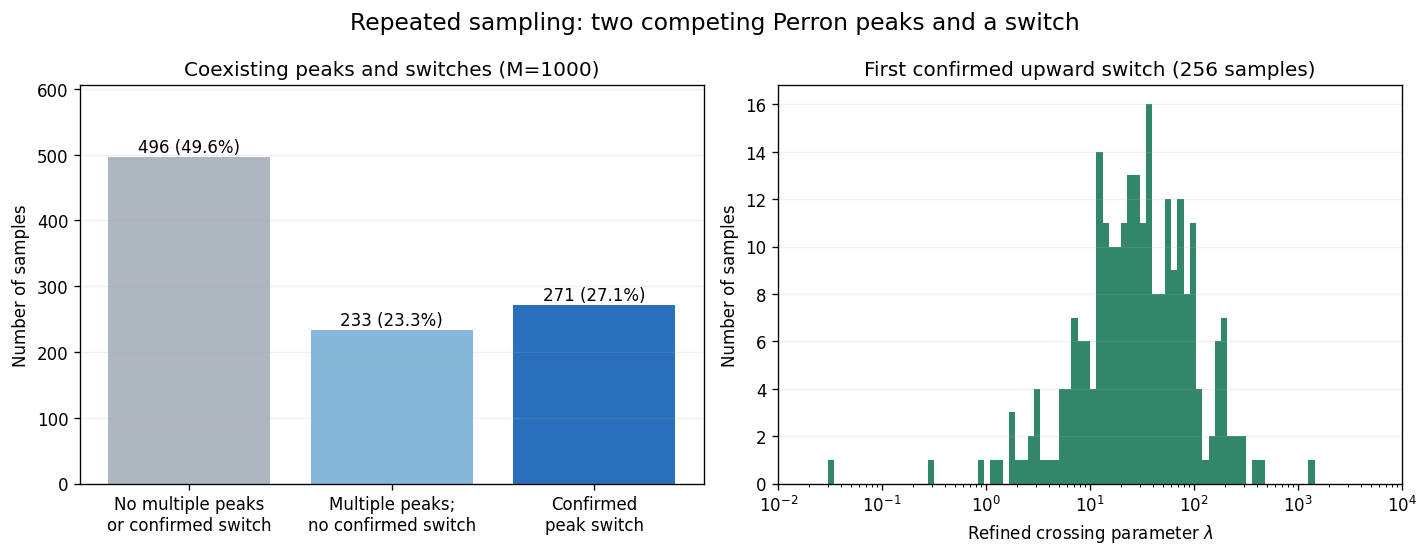

Saved PDF: /Users/iljasukhanov/MASTERARBEIT/Code/Code_kde/outputs/pdfs/spectral_lambda_jump_study/002_independent_samples_the_selected_peak_changes_sides.pdf


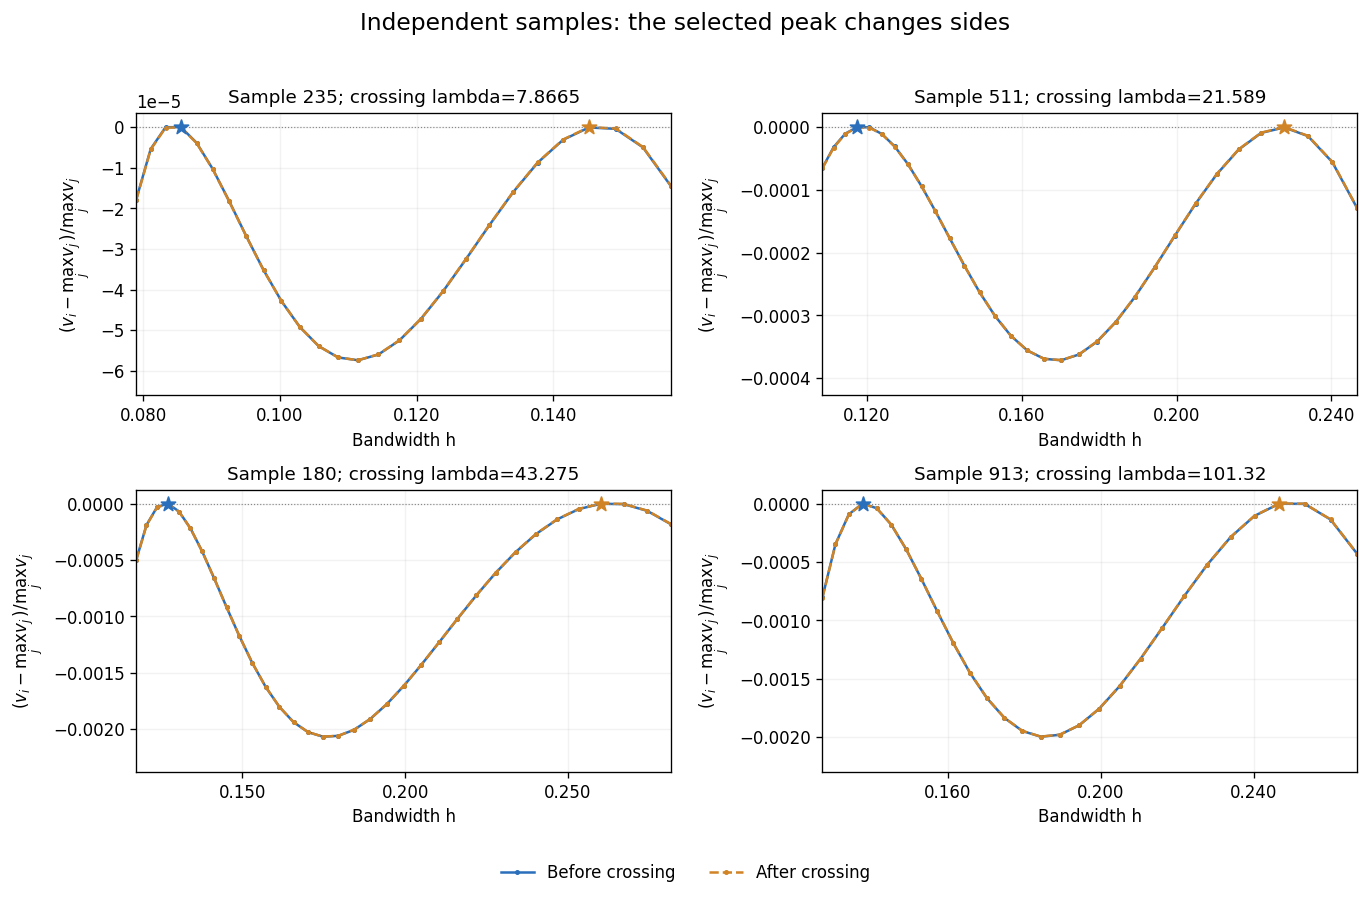

Saved summary and independent-sample previews: /Users/iljasukhanov/MASTERARBEIT/Code/Code_kde/outputs/images/spectral_lambda_jump_study/peak_switches


In [11]:
peak_switch_image_directory = peak_switch_module.plot_analysis(peak_switch_analysis)
print(f"Saved summary and independent-sample previews: {peak_switch_image_directory}")

The first figure reports sample-level outcomes and the parameter at the first confirmed upward peak switch in each sample. The second shows four independent samples selected deterministically across the crossing-parameter distribution, with a star marking the selected maximum immediately before/after each refined crossing. Peak count and prominence sensitivity results are printed above.

Outputs under the printed `peak_switches` directory:

- `sample_results.csv`: one row per sample, peak counts and number of confirmed switches.
- `confirmed_switches.csv`: all accepted crossings, peak/valley locations and residual diagnostics.
- `candidate_crossings.json`: accepted and rejected candidate intervals, with rejection reasons.
- `checkpoint.json`: resumable per-sample results and peak counts at every sampled lambda.
- `summary.json`: counts, method settings, and sensitivity results.
- `example_profiles.json`: actual vectors used in the independent-sample plots.

Every displayed figure is also exported automatically to `outputs/pdfs/spectral_lambda_jump_study/`.

## Experiment 3: does the original switch survive numerical refinement?

Use the original Figure 3.3 sample (seed 20260823, n=200). Compare an independent dense eigensolver on the original similarity matrix with the shared solver, replace FFT integration by the analytic Gaussian KDE inner products, increase the FFT domain/resolution, and refine the entire geometric bandwidth grid while keeping its endpoints fixed.

These are original numerical checks of the selector. They provide evidence about numerical accuracy and grid sensitivity, without proving a continuum limit. The crossing parameter can change when the bandwidth grid changes. Smooth eigenvector variation at a simple eigenvalue is supported by [Greenbaum, Li and Overton, Theorem 2, p. 467](https://cs.nyu.edu/~overton/papers/pdffiles/EigVecPert.pdf); choosing its largest component can still change discontinuously (our deduction).

The helper also follows a saved sample with two competing peaks and no detected switch (repetition 835, zero based) on 501 lambda values. Results are stored in `outputs/data/spectral_lambda_jump_study/numerical_artefact_checks/results.json`. Cached results concern the original sample and fixed settings above, independently of Experiment 1 preview settings.


In [12]:
artefact_helper_path = (code_directory / "outputs" / "analysis" /
                        "spectral_lambda_jump_study" / "numerical_artefact_checks.py")
artefact_spec = importlib.util.spec_from_file_location("numerical_artefact_checks", artefact_helper_path)
artefact_module = importlib.util.module_from_spec(artefact_spec)
artefact_spec.loader.exec_module(artefact_module)
artefact_result_path = artefact_module.OUTPUT_DIRECTORY / "results.json"
if artefact_result_path.is_file():
    artefact_report = json.loads(artefact_result_path.read_text())
    print(f"Loaded numerical checks: {artefact_result_path}")
else:
    artefact_report = artefact_module.run_checks()

print("Bandwidth-grid refinement (original Figure 3.3 sample):")
artefact_grid_table = pd.DataFrame([
    {"bandwidth_grid_points": row["bandwidth_grid_size"],
     "lambda_crossing": row["lambda_crossing"],
     "lower_peak_h": row["lower_peak_h_at_crossing"],
     "upper_peak_h": row["upper_peak_h_at_crossing"],
     "relative_valley_depth": row["relative_valley_depth_at_crossing"]}
    for row in artefact_report["bandwidth_grid_refinement"]
])
display(artefact_grid_table)
print(f"Analytic integration crossing: {artefact_report['analytic_integration']['lambda_crossing']:.10f}")
print("Largest dense/shared component discrepancy:",
      max(row["maximum_component_discrepancy"] for row in artefact_report["independent_dense_solver"]))
print("FFT refinements:",
      [(row["half_width"], row["spatial_points"], row["lambda_crossing"])
       for row in artefact_report["fft_refinement"]])
print("Example with no detected switch:",
      {key: value for key, value in artefact_report["no_switch_example"].items() if key != "profiles"})


Loaded numerical checks: /Users/iljasukhanov/MASTERARBEIT/Code/Code_kde/outputs/data/spectral_lambda_jump_study/numerical_artefact_checks/results.json
Bandwidth-grid refinement (original Figure 3.3 sample):
Analytic integration crossing: 17.8737506446
Largest dense/shared component discrepancy: 1.6046192152785466e-17
FFT refinements: [(12.0, 8192, 17.873750644610006), (16.0, 16384, 17.873750644643962), (16.0, 32768, 17.87375064461143)]
Example with no detected switch: {'repetition_zero_based': 835, 'lambda_grid': 'geomspace(0.01, 200, 501)', 'profiles_with_multiple_resolved_peaks': 484, 'minimum_relative_height_gap_while_multiple_peaks_resolved': 7.424972155248327e-06, 'maximum_adjacent_selected_index_change': 1}


bandwidth_grid_points,lambda_crossing,lower_peak_h,upper_peak_h,relative_valley_depth
201,17.873751,0.111421,0.204921,0.000141
401,18.079943,0.112907,0.202225,0.000135
801,18.176591,0.113657,0.202225,0.000131
1601,18.224201,0.113657,0.202896,0.000130


## Experiment 4: which aspects of the samples accompany multiple peaks?

This section uses the archived **1,000 original samples**, independently of preview settings in Experiment 1. The target is the existing sample-level classification: multiple Perron peaks were observed somewhere on the lambda grid or at a refined crossing. It is not the switch/no-switch target.

An original deterministic observation from the [analytic Gaussian KDE inner products](kde_tools/density.py): the divergence matrix depends on the pairwise distances between sample points. Translation, reflection, and permutation preserve the exact matrix. Matching a few moments does not match all these distances.

Compare three fixed feature sets: ordinary spread/shape/tail summaries; those summaries plus point-spacing features and fractions of standardized pair distances below seven radii; and the entire profile of the squared L2 norm of $d\hat f_h/d\log h$. The last feature is an original analytic derivation from the same Gaussian inner products, checked against direct spatial integration. It measures how the KDE changes as bandwidth varies; counting its minima is not a universal criterion for Perron peak counts.

Each observation receives a prediction from a standardized logistic model trained on the other four folds. The feature sets, regularization, and folds are fixed without selecting them on held-out scores. Prediction scores and group averages describe associations; they do not identify a causal sample feature.

The illustration matches one-peak and two-peak samples on SD, absolute skewness, excess kurtosis, and IQR/SD. The two-peak candidate must also pass the stricter prominence sensitivity filter $10^{-6}\max v$ at lambda 0.01. At small lambda, local minima of divergence row sums correspond to local maxima of the first-order Perron approximation (see [first_order_perron_vector](kde_tools/similarities.py)); the examples' actual profiles and row-sum minima are saved.

A separate constructed interpolation redistributes sorted points between standardized examples while fixing n, mean, and sample SD at every step. This tests whether the peak count can change with those quantities fixed; other shape features can change. It is not an additional independent-sampling experiment.


In [13]:
geometry_helper_path = (code_directory / "outputs" / "analysis" /
                        "spectral_lambda_jump_study" / "sample_geometry_analysis.py")
geometry_spec = importlib.util.spec_from_file_location("sample_geometry_analysis", geometry_helper_path)
geometry_module = importlib.util.module_from_spec(geometry_spec)
geometry_spec.loader.exec_module(geometry_module)
geometry_result_path = geometry_module.OUTPUT_DIRECTORY / "summary.json"
if geometry_result_path.is_file():
    geometry_summary = json.loads(geometry_result_path.read_text())
else:
    geometry_summary = geometry_module.run_analysis()

print(f"Archived samples: {geometry_summary['samples']}; "
      f"one peak observed throughout checked profiles: {geometry_summary['one_peak_observed_samples']}; "
      f"multiple peaks observed somewhere: {geometry_summary['multiple_peaks_observed_samples']}")
geometry_scores = pd.DataFrame([
    {"features": name, "out_of_fold_AUC": result["out_of_fold_roc_auc"],
     "out_of_fold_balanced_accuracy_percent": 100 * result["out_of_fold_balanced_accuracy"]}
    for name, result in geometry_summary["models"].items()
])
display(geometry_scores.round(3))
geometry_example_table = pd.DataFrame([
    {"sample_id_zero_based": example["repetition"],
     "Perron_peaks_at_lambda_0_01": len(example["perron_peak_h"]),
     **example["ordinary_features"]}
    for example in geometry_summary["matched_example_profiles"]
])
display(geometry_example_table.round(4))
geometry_interpolation = geometry_summary["variance_controlled_interpolation"]
print("Constructed interpolation with constant mean and sample SD:")
print([(row["interpolation_fraction"], row["resolved_peak_count"])
       for row in geometry_interpolation["profiles"]])
print("Largest mean/SD deviation:",
      max(abs(row["sample_mean"]) for row in geometry_interpolation["profiles"]),
      max(abs(row["sample_sd"] - geometry_interpolation["common_sample_sd"])
          for row in geometry_interpolation["profiles"]))
print(f"Saved features, scores, and example profiles: {geometry_module.OUTPUT_DIRECTORY}")


Archived samples: 1000; one peak observed throughout checked profiles: 496; multiple peaks observed somewhere: 504
Constructed interpolation with constant mean and sample SD:
[(0.0, 1), (0.05, 1), (0.1, 1), (0.15000000000000002, 2), (0.2, 2), (0.25, 2), (0.30000000000000004, 3), (0.35000000000000003, 2), (0.4, 2), (0.45, 2), (0.5, 2), (0.55, 2), (0.6000000000000001, 2), (0.65, 2), (0.7000000000000001, 2), (0.75, 2), (0.8, 2), (0.8500000000000001, 2), (0.9, 2), (0.9500000000000001, 2), (1.0, 2)]
Largest mean/SD deviation: 1.4210854715202004e-16 1.1102230246251565e-16
Saved features, scores, and example profiles: /Users/iljasukhanov/MASTERARBEIT/Code/Code_kde/outputs/data/spectral_lambda_jump_study/2ce04db2a16e/sample_geometry


features,out_of_fold_AUC,out_of_fold_balanced_accuracy_percent
ordinary_distribution_summaries,0.576,56.381
summaries_and_spacing,0.823,75.682
multiscale_kde_change_profile,0.881,79.491


sample_id_zero_based,Perron_peaks_at_lambda_0_01,sample_sd,abs_skewness,excess_kurtosis,iqr_over_sd,maximum_abs_standardized_value
44,1,1.0032,0.1787,0.1564,1.2935,3.0322
749,2,1.0063,0.1727,0.1316,1.2879,3.0091


Saved PDF: /Users/iljasukhanov/MASTERARBEIT/Code/Code_kde/outputs/pdfs/spectral_lambda_jump_study/001_sample_spacing_and_the_number_of_perron_peaks.pdf
Saved matched-sample illustration: /Users/iljasukhanov/MASTERARBEIT/Code/Code_kde/outputs/images/spectral_lambda_jump_study/sample_geometry/matched_samples_one_vs_two_peaks.png


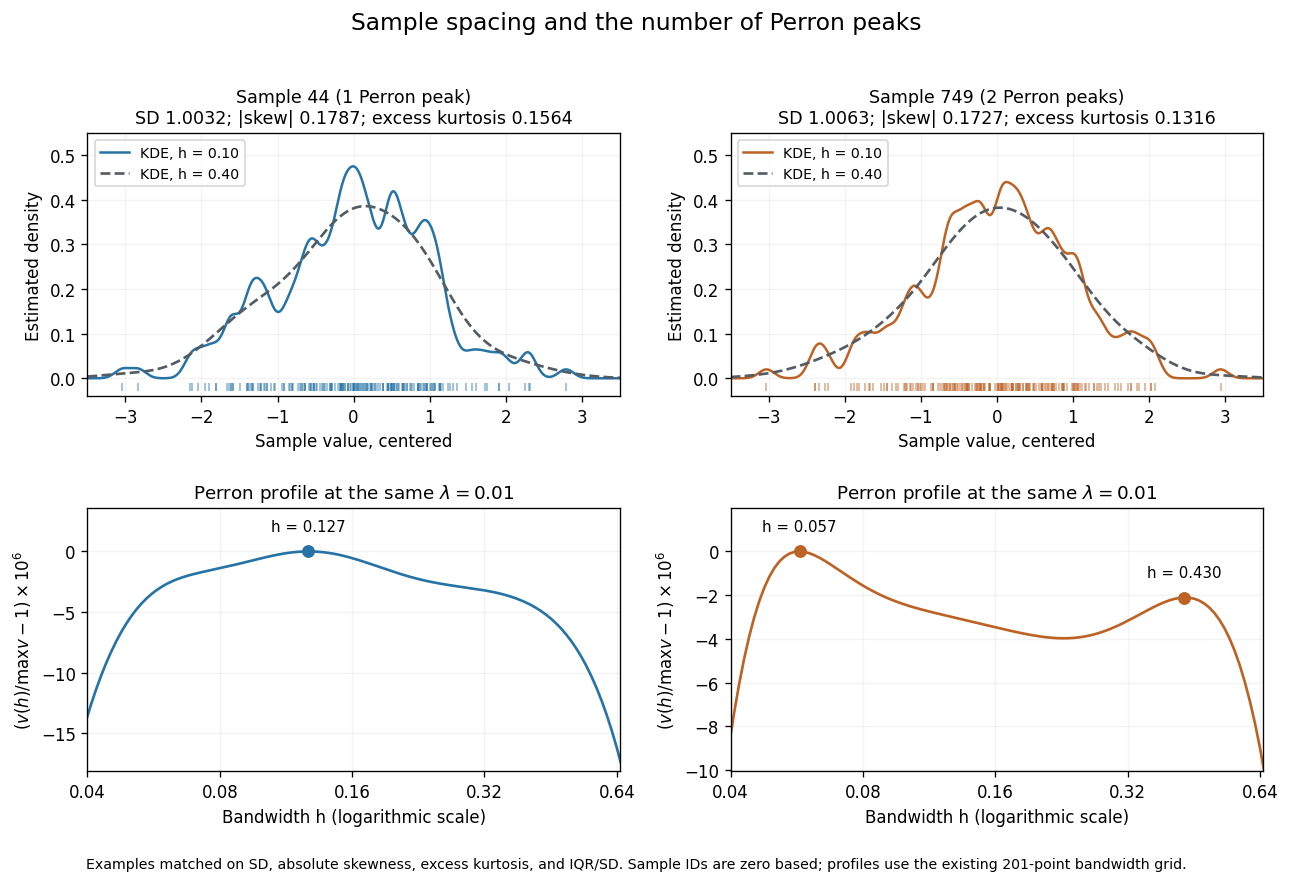

In [14]:
geometry_image_path = geometry_module.plot_matched_examples(geometry_summary)
print(f"Saved matched-sample illustration: {geometry_image_path}")


## Experiment 5: separate a sample effect from a numerical effect

This section studies the **peak switch itself**, including evaluation between bandwidth nodes. It uses the archived Figure 3.3 sample and the same archived 1,000 independent samples; it does not use a concentration statistic.

There are two numerical questions: does changing the eigensolver or density integration change the result (Experiment 3), and does changing the bandwidth grid change the competing maxima (this section)? A further sampling question is whether the competition appears without a realized random sample.

For the original sample, define the kernel-based extension

$$\phi_N(h;\lambda)=\frac{1}{\rho(S)}\sum_{j=1}^N e^{-\lambda D(h,h_j)}v_j(\lambda).$$

It agrees with the matrix Perron vector at the basis nodes and evaluates the actual KDE divergence at new bandwidths. This is a **Nyström approximation**, not a fitted interpolation. Equal weights correspond to a uniform measure in $\log h$ on the fixed interval $h\in[0.01,2]$. Compare endpoint and midpoint quadrature grids with $N=201,401,801,1601$; solve analytically differentiated stationary-point equations for the two peaks and find the lambda where their heights agree. The quadrature construction follows [Simons and Wang, numerical solution, Eqs. (82)-(86)](https://geoweb.princeton.edu/people/simons/PDF/reprints/GEM-2011.pdf). The convergence reported here is numerical evidence, rather than a certified result for the limiting integral operator.

For the repeated samples, compare the **first 200 archived samples**, chosen before looking at their refined classifications, on 201/401/801 endpoint grids and a 401 midpoint grid. A descriptive **sharp switch** requires the existing resolved separated-peak crossing test **and** a ratio of peak bandwidths at the crossing of at least **1.20**. This 20% cutoff is a declared choice; sensitivity at 10% and 50% is also saved. Candidate lambda intervals have an endpoint bandwidth change of at least 5%, independent of grid resolution. The original 101-point lambda scan can miss sufficiently short events.

Sources for the implementation: [continuous kernel and derivatives](outputs/analysis/spectral_lambda_jump_study/continuous_bandwidth_switch.py), [paired sample/grid diagnostics](outputs/analysis/spectral_lambda_jump_study/robust_switch_diagnostics.py), and [separated-peak crossing detector](outputs/analysis/spectral_lambda_jump_study/repeated_peak_switch_analysis.py).

In [15]:
analysis_directory = code_directory / "outputs/analysis/spectral_lambda_jump_study"
if str(analysis_directory) not in sys.path:
    sys.path.insert(0, str(analysis_directory))
# Normal imports also allow the paired helper's worker functions to be pickled.
import robust_switch_diagnostics as robust_module
import continuous_bandwidth_switch as continuous_module

robust_summary_path = robust_module.OUTPUT_DIRECTORY / "summary.json"
robust_summary = (json.loads(robust_summary_path.read_text()) if robust_summary_path.is_file()
                  else robust_module.run_analysis())
continuous_summary_path = continuous_module.OUTPUT_DIRECTORY / "summary.json"
continuous_summary = (json.loads(continuous_summary_path.read_text()) if continuous_summary_path.is_file()
                      else continuous_module.run_analysis())
fragile_path = robust_module.OUTPUT_DIRECTORY / "fragile_case_68.json"
fragile_report = (json.loads(fragile_path.read_text()) if fragile_path.is_file()
                  else robust_module.audit_fragile_case())
print("Loaded paired samples and deterministic controls:", robust_summary_path)
print("Loaded kernel-based peak and derivative checks:", continuous_summary_path)

Loaded paired samples and deterministic controls: /Users/iljasukhanov/MASTERARBEIT/Code/Code_kde/outputs/data/spectral_lambda_jump_study/2ce04db2a16e/numerical_vs_sampling/summary.json
Loaded kernel-based peak and derivative checks: /Users/iljasukhanov/MASTERARBEIT/Code/Code_kde/outputs/data/spectral_lambda_jump_study/continuous_bandwidth_switch/summary.json


In [16]:
continuous_table = pd.DataFrame([
    {"nodes": row["grid_size"], "placement": row["placement"],
     "lambda_crossing": row["lambda_crossing"],
     "smaller_peak_h": row["peaks"][0]["h"], "larger_peak_h": row["peaks"][1]["h"],
     "peak_bandwidth_ratio": row["peak_bandwidth_ratio"],
     "relative_valley_depth": row["relative_valley_depth"]}
    for row in continuous_summary["convergence"]
])
print("Original Figure 3.3 sample: stationary maxima of the kernel extension")
display(continuous_table)
paired_table = pd.DataFrame([
    {"grid": name, "samples": row["samples"], "sharp_switch_samples": row["samples_with_sharp_switch"],
     "same_classification_as_201": row["same_classification_as_original_201"],
     "original_switches_persisting": row["original_switch_persists"],
     "samples_at_10_percent_cutoff": row["sensitivity_by_minimum_bandwidth_ratio"]["1.1"],
     "samples_at_50_percent_cutoff": row["sensitivity_by_minimum_bandwidth_ratio"]["1.5"]}
    for name, row in robust_summary["paired_scenarios"].items()
])
print("Matched 200 samples: separated peak crossings with >=20% bandwidth separation")
display(paired_table)
print("Full original 1,000-sample bank, same >=20% definition:")
print(robust_summary["original_1000_sample_sharp_switch_frequency"])
print("Wilson intervals use the nominal 95% score interval; see the cited documentation below.")

Original Figure 3.3 sample: stationary maxima of the kernel extension
Matched 200 samples: separated peak crossings with >=20% bandwidth separation
Full original 1,000-sample bank, same >=20% definition:
{'samples': 1000, 'samples_with_sharp_switch': 259, 'frequency': 0.259, 'wilson_95_percent_interval': [0.23280623499082614, 0.28703826259921145]}
Wilson intervals use the nominal 95% score interval; see the cited documentation below.


,nodes,placement,lambda_crossing,smaller_peak_h,larger_peak_h,peak_bandwidth_ratio,relative_valley_depth
0,201,endpoint,17.887280,0.112905,0.204162,1.808258,0.000142
1,401,endpoint,18.079707,0.113412,0.203259,1.792221,0.000135
2,801,endpoint,18.175987,0.113668,0.202807,1.784206,0.000131
3,1601,endpoint,18.224145,0.113797,0.202581,1.780199,0.000130
4,201,midpoint,18.272053,0.113924,0.202359,1.776263,0.000128
5,401,midpoint,18.272249,0.113926,0.202356,1.776210,0.000128
6,801,midpoint,18.272298,0.113926,0.202355,1.776196,0.000128
7,1601,midpoint,18.272311,0.113926,0.202355,1.776193,0.000128


,grid,samples,sharp_switch_samples,same_classification_as_201,original_switches_persisting,samples_at_10_percent_cutoff,samples_at_50_percent_cutoff
0,endpoint_201,200,58,200,58,61,47
1,endpoint_401,200,57,199,57,59,47
2,endpoint_801,200,57,199,57,59,48
3,midpoint_401,200,57,199,57,59,47


### Deterministic Gaussian references and the discordant sample

Two references are scanned on 201/801 bandwidth nodes and 601 lambda values from $0.01$ to $10^4$: the population family $f_h=N(0,1+h^2)$, and the expected empirical divergence for $n=200$. Both have only one resolved interior Perron maximum at every tested lambda.

**Our derivation** of the second reference uses the exact Gaussian KDE Gram formula in [density.py, `exact_gaussian_kde_l2_gram`](kde_tools/density.py). For $s=h_i^2+h_j^2$, diagonal sample pairs have difference zero; distinct independent standard Gaussian pairs have difference distributed as $N(0,2)$. Hence

$$\mathbb E[G_{ij}]=\frac{1}{n\sqrt{2\pi s}}+\frac{1-1/n}{\sqrt{2\pi(s+2)}},\qquad
\mathbb E[D_{ij}]=\tfrac12(\mathbb E[G_{ii}]+\mathbb E[G_{jj}]-2\mathbb E[G_{ij}]).$$

The vector of $\exp(-\lambda\mathbb E[D])$ is a deterministic reference, **not** $\mathbb E[v]$ or the vector of $\mathbb E[\exp(-\lambda D)]$.

Repetition 68 is the sole discordant sharp-switch classification in the paired cohort: the 201-node crossing at $\lambda\approx0.031792$ has a relative valley depth of only $2.71\times10^{-7}$. All three refinements still produce two peaks, but the larger-bandwidth peak remains higher. A targeted 81-point lambda scan from $0.01$ to $1$, plus $0.0001$ and $0.001$, also finds no reversal on those grids. This is evidence of **grid sensitivity in one shallow case**, rather than justification for treating every detected switch as equally robust. See the [saved targeted audit](outputs/data/spectral_lambda_jump_study/2ce04db2a16e/numerical_vs_sampling/fragile_case_68.json).

The reported sampling intervals are Wilson score intervals, implemented as documented in [statsmodels, `proportion_confint`, method `wilson`](https://www.statsmodels.org/stable/generated/statsmodels.stats.proportion.proportion_confint.html). They concern the probability of the **specified numerical detector** under the stated sample law and grids.

In [17]:
display(pd.DataFrame(robust_summary["deterministic_controls"])[[
    "reference", "bandwidth_grid_size", "maximum_resolved_peak_count",
    "lambda_points_with_multiple_peaks", "confirmed_sharp_switches"]])
fragile_table = pd.DataFrame([
    {"nodes": row["grid_size"], "placement": row["placement"],
     "maximum_lower_minus_upper_relative_height": max(
         value["relative_lower_minus_upper_height"] for value in row["values"]),
     "minimum_lower_minus_upper_relative_height": min(
         value["relative_lower_minus_upper_height"] for value in row["values"])}
    for row in fragile_report["scenarios"]
])
print("Repetition 68: competing peak height order on the targeted lambda scan")
display(fragile_table)

Repetition 68: competing peak height order on the targeted lambda scan


,reference,bandwidth_grid_size,maximum_resolved_peak_count,lambda_points_with_multiple_peaks,confirmed_sharp_switches
0,population_densities,201,1,0,0
1,expected_empirical_divergence_n200,201,1,0,0
2,population_densities,801,1,0,0
3,expected_empirical_divergence_n200,801,1,0,0


,nodes,placement,maximum_lower_minus_upper_relative_height,minimum_lower_minus_upper_relative_height
0,201,endpoint,7.856165e-09,-0.000024
1,401,endpoint,-1.702393e-10,-0.000024
2,801,endpoint,-3.015833e-10,-0.000024
3,401,midpoint,-4.323247e-10,-0.000025


Saved PDF: /Users/iljasukhanov/MASTERARBEIT/Code/Code_kde/outputs/pdfs/spectral_lambda_jump_study/001_figure_3_3_sample_two_smooth_peaks_exchange_dominance.pdf
Saved continuous peak crossing illustration: /Users/iljasukhanov/MASTERARBEIT/Code/Code_kde/outputs/images/spectral_lambda_jump_study/numerical_vs_sampling/continuous_peak_height_crossing.png


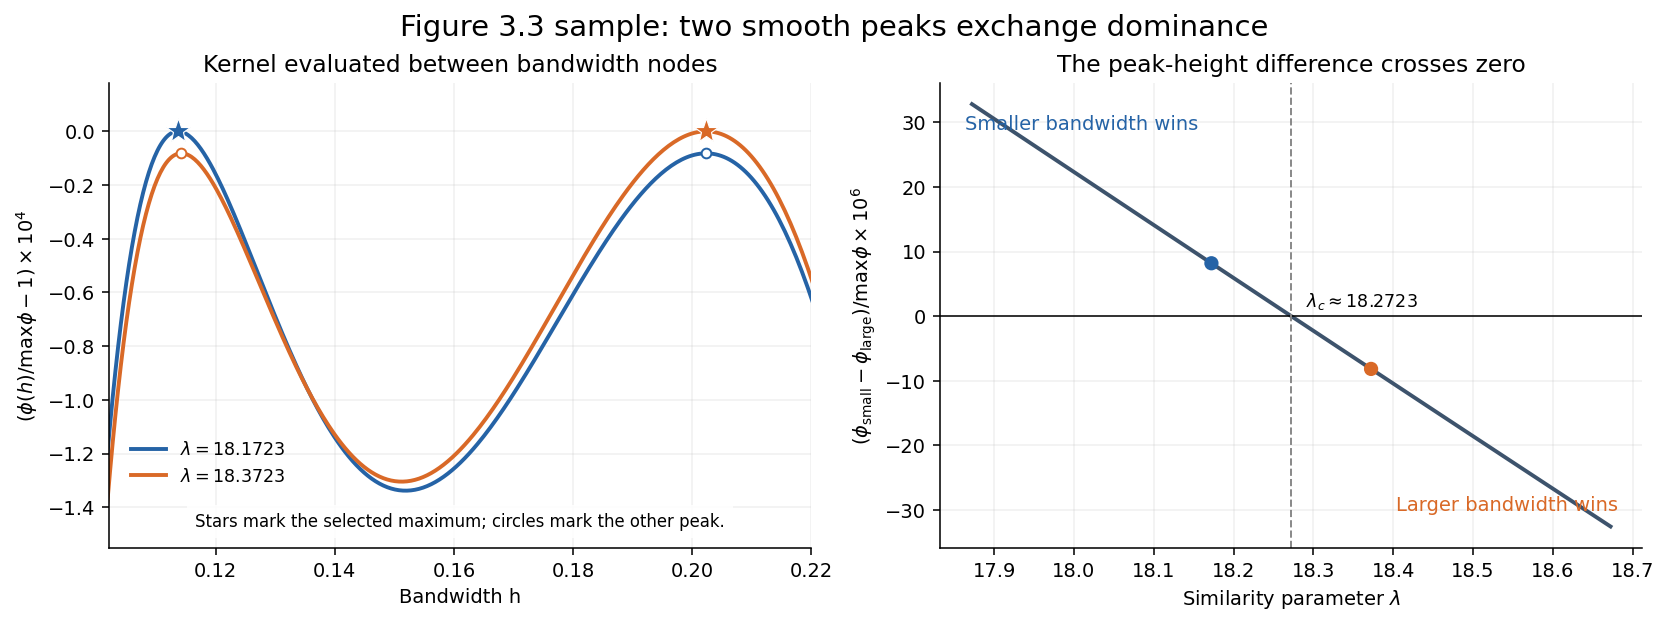

In [18]:
continuous_image_path = continuous_module.plot_analysis(continuous_summary)
print("Saved continuous peak crossing illustration:", continuous_image_path)

### What this evidence establishes, and what remains a probabilistic question

For the Figure 3.3 sample, the off-node kernel evaluation has two stationary maxima with negative curvature, a valley between them, and a sign-changing peak-height difference. Midpoint-grid crossing locations converge to about $18.2723$, with peak bandwidths about $0.11393$ and $0.20235$, a roughly 77.6% separation. This differs from the original **discrete 201-node** crossing at $17.87375$: the switch location depends on the numerical definition, while the two-peak competition persists. Do not replace the original Figure 3.3 lambda value with the limiting-grid estimate.

In the paired 200 samples, 57 of the original 58 sharp-switch samples persist on every refinement, with 199/200 identical classifications. The full original-grid bank has 259/1,000 samples with the stricter 20% separation criterion (25.9%; nominal Wilson 95% interval 23.3%-28.7%). Experiment 2's 271 samples included smaller resolved switches, so the two counts use different definitions. The deterministic references and the matched refinement results support a reproducible **sample-dependent effect of this selector**; the repetition-68 exception shows that some shallow crossings are grid sensitive.

The underlying Perron vector is smooth in lambda in exact arithmetic. The matrix $S_{ij}=\exp(-\lambda D_{ij})$ is strictly positive for finite lambda, so its Perron eigenvalue is simple ([Magal, Theorem 4.13, slide 36](https://www.math.u-bordeaux.fr/~pmagal100p/Lectures/ODE-Volume-1/Magal-Chap-4-June-2023.pdf)); analytic matrix dependence and a simple eigenvalue permit analytic eigenvectors ([Greenbaum, Li and Overton, Theorem 2, p. 467](https://cs.nyu.edu/~overton/papers/pdffiles/EigVecPert.pdf)). Our conclusion about the selector follows from these facts: a smoothly changing vector can have two distant maxima whose heights exchange order. Selecting only its global maximum converts that smooth crossing into a discontinuous selected bandwidth. The observed spectral gap near the original sample's refined crossings remains about 0.82, rather than indicating a near-degenerate Perron eigenvalue.

**Mechanistic interpretation from this model:** the sample enters $D$ through all pairwise data distances in the exact Gaussian Gram matrix. Different realized spacing patterns therefore change the similarity geometry of the bandwidth family. Increasing lambda reduces the relative weight of more dissimilar bandwidth pairs; different bandwidth regions can then exchange Perron dominance. In a one-peak sample there is no competitor; with two peaks the height difference may stay of one sign or cross zero. At small lambda, the first-order formula implemented in [similarities.py, `first_order_perron_vector`](kde_tools/similarities.py) makes the maximum correspond to a minimum divergence row sum. This helps connect the low-lambda peak structure directly to the sample-dependent divergence matrix; it does not give a complete sample-level classification theorem.

The jump is an interesting empirical feature of this procedure, but it is not by itself proof of a new probabilistic phase transition. The unresolved statistical questions are which random sample geometries produce robust crossings, how their probability depends on sample size and the bandwidth domain/measure, and the distribution of the crossing lambda. These checks do not establish novelty, an exhaustive continuous-lambda count, or a certified integral-operator limit. They do distinguish the robust Figure 3.3 behavior from a floating-point failure and from the observed shallow grid-sensitive example.